# Cortes preprocesados

**Entrada:** `series_elegidas.csv` (output del notebook 02: 656 series Sagital FS, una por estudio, con contraste,
geometría y `lado_final`) + los DICOM de la competencia.
**Salida:** un `.npy` por estudio, de forma **[15, 256, 256]** en `float16`, más un índice `indice_npy.csv`.

**Decisiones (tomadas en el 02):**
1. Cortes ordenados por posición física (`ImagePositionPatient` · normal).
2. **Canal 0 = lado medial**, según `lado_final`.
3. Cortes elegidos **en mm respecto al centro del volumen**: 15 posiciones de −28 a +28 mm cada 4 mm.
4. Cada corte de salida = **promedio de los cortes dentro de ±1.75 mm** (en las 3D finas; en las 2D, el más cercano).
5. Intensidad por volumen: recorte entre los percentiles 0.5 y 99.5 → **[0, 1]**.
6. Redimensionado a **256 × 256**.
7. Guardado en `float16`.



In [1]:
# Ubicar las entradas (3 niveles, máx. 6 elementos por carpeta)
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pydicom

def arbol(ruta, nivel=0, max_nivel=4, max_items=6):
    items = sorted(os.listdir(ruta))
    for nombre in items[:max_items]:
        p = os.path.join(ruta, nombre)
        print("    " * nivel + ("📁 " if os.path.isdir(p) else "📄 ") + nombre)
        if os.path.isdir(p) and nivel + 1 < max_nivel and nombre != "train_series" and nombre != "test_series":
            arbol(p, nivel + 1, max_nivel, max_items)
    if len(items) > max_items:
        print("    " * nivel + f"... (+{len(items) - max_items} más)")

arbol("/kaggle/input")


📁 competitions
    📁 rsna-knee-abnormality-detection
        📄 sample_submission.csv
        📄 test.csv
        📁 test_series
        📄 test_series.csv
        📄 train.csv
        📁 train_series
        ... (+1 más)
📁 datasets
    📁 bryansalva
        📁 rodilla-cnn
            📄 dataset_cnn.csv
            📄 series_cnn.csv
📁 notebooks
    📁 bryansalva
        📁 02-preprocesamiento-dicom
            📄 __notebook__.ipynb
            📄 __output__.json
            📄 __results__.html
            📁 __results___files
            📄 custom.css
            📄 series_elegidas.csv


In [2]:
# 10.3a — Rutas y carga de las series elegidas (output del notebook 02)
DATA = Path("/kaggle/input/competitions/rsna-knee-abnormality-detection")
MIO  = Path("/kaggle/input/datasets/bryansalva/rodilla-cnn")
NB02 = Path("/kaggle/input/notebooks/bryansalva/02-preprocesamiento-dicom")
OUT  = Path("/kaggle/working")

series = pd.read_csv(NB02 / "series_elegidas.csv")
assert series["StudyInstanceUID"].is_unique and series["lado_final"].notna().all()

print(series.shape)
print("split:      ", series["split"].value_counts().to_dict())
print("lado_final: ", series["lado_final"].value_counts().to_dict())
print("lado_fuente:", series["lado_fuente"].value_counts().to_dict())
print("contraste:  ", series["contraste"].value_counts().to_dict())
series.head(3)


(656, 15)
split:       {'train': 480, 'val': 120, 'test': 56}
lado_final:  {'R': 359, 'L': 297}
lado_fuente: {'x': 597, 'visual': 35, 'dicom/texto': 22, 'x_dudosa': 2}
contraste:   {'DP': 571, 'T2': 85}


,StudyInstanceUID,SeriesInstanceUID,split,contraste,n_cortes,SerieN,TE,Grosor,Pixel,Filas,Cols,fabricante,x_centro,lado_final,lado_fuente
0,1.2.826.0.1.3680043.8.498.10013663742400736029...,1.2.826.0.1.3680043.8.498.70243599053060014636...,train,T2,35,5,82.00,3.0,"[0.5, 0.5]",320,320,SIEMENS,-102.193806,R,x
1,1.2.826.0.1.3680043.8.498.10018552945042470316...,1.2.826.0.1.3680043.8.498.13316012614172613981...,val,DP,41,7,40.28,2.0,"[0.293, 0.293]",512,512,GE,57.750687,L,x
2,1.2.826.0.1.3680043.8.498.10081117556977868957...,1.2.826.0.1.3680043.8.498.18034687025255390862...,train,DP,29,7,36.00,3.0,"[0.25, 0.25]",640,640,SIEMENS,-80.343415,R,x


In [3]:
# 10.3b — Leer una serie completa ordenada por x (mm). En DICOM, +x = izquierda del paciente
def carpeta_serie(fila):
    return DATA / "train_series" / fila.StudyInstanceUID / fila.SeriesInstanceUID

def leer_volumen(fila):
    cortes = [pydicom.dcmread(a) for a in carpeta_serie(fila).glob("*.dcm")]
    xs = np.array([float(c.ImagePositionPatient[0]) for c in cortes])
    orden = np.argsort(xs)                                   # de la derecha del paciente a la izquierda
    vol = np.stack([cortes[i].pixel_array for i in orden]).astype(np.float32)
    return vol, xs[orden]

# Prueba con una DP típica de 29 cortes
fila = series[(series.n_cortes == 29) & (series.contraste == "DP")].iloc[0]
vol, xs = leer_volumen(fila)
print("Volumen:", vol.shape, vol.dtype, "| lado:", fila.lado_final, "| fabricante:", fila.fabricante)
print("x de los cortes (mm):", xs[:3].round(1), "...", xs[-3:].round(1))
print("Paso entre cortes (mm):", np.unique(np.diff(xs).round(2)))
print("Centro x calculado:", round(xs.mean(), 1), "| x_centro del 02:", round(fila.x_centro, 1))
print("Intensidad: p0.5 =", np.percentile(vol, 0.5), "| p99.5 =", np.percentile(vol, 99.5), "| max =", vol.max())


Volumen: (29, 640, 640) float32 | lado: R | fabricante: SIEMENS
x de los cortes (mm): [-130.2 -126.7 -123.1] ... [-37.6 -34.  -30.4]
Paso entre cortes (mm): [3.56]
Centro x calculado: -80.3 | x_centro del 02: -80.3
Intensidad: p0.5 = 1.0 | p99.5 = 454.0 | max = 960.0


### Interpretación
- El CSV del 02 llegó completo: 656 series, todas con lado (R 359 / L 297), 571 DP / 85 T2, splits 480/120/56.
- `leer_volumen()` en una DP Siemens de 29 cortes (rodilla R): volumen (29, 640, 640).
- **Paso entre cortes 3.56 mm** medido sobre x (frente a 3.6 mm sobre la normal): la sagital está levemente inclinada
  (~8°, cos 8° ≈ 0.99) → diferencia despreciable; ordenar y medir sobre x es válido.
- **Centro x = −80.3 mm, idéntico al `x_centro` del 02** → el notebook 02 y el 03 usan el mismo sistema de coordenadas.
- Intensidad: p0.5 = 1, p99.5 = 454, máximo 960 → al recortar en p99.5 se descarta solo el 0.5 % más brillante
  (líquido o vasos muy intensos, artefactos), que si no comprimiría el resto de la imagen hacia el negro.


In [4]:
#  — Leer una serie completa ordenada por x (mm). En DICOM, +x = izquierda del paciente
def carpeta_serie(fila):
    return DATA / "train_series" / fila.StudyInstanceUID / fila.SeriesInstanceUID

def leer_volumen(fila):
    cortes = [pydicom.dcmread(a) for a in carpeta_serie(fila).glob("*.dcm")]
    xs = np.array([float(c.ImagePositionPatient[0]) for c in cortes])
    orden = np.argsort(xs)                                   # de la derecha del paciente a la izquierda
    vol = np.stack([cortes[i].pixel_array for i in orden]).astype(np.float32)
    ori = np.array(cortes[0].ImageOrientationPatient, float) # (dirección de las columnas →, dirección de las filas ↓)
    return vol, xs[orden], ori


In [5]:
# — Preprocesamiento: orientar → muestrear 15 posiciones (mm) → normalizar → 256×256 → float16
import cv2

OFFSETS = np.arange(-28, 29, 4)   # 15 posiciones en mm: −28 (medial) … 0 (centro) … +28 (lateral)
MEDIA_LAMINA = 1.75               # mm a cada lado → lámina de 3.5 mm
TAM = 256

def orientar_plano(vol, ori):
    """Deja anterior a la izquierda y superior arriba. DICOM: +y = posterior, +z = superior."""
    r, c = ori[:3], ori[3:]
    if abs(r[2]) > abs(r[1]):                 # imagen girada 90°: filas y columnas intercambiadas
        vol, (r, c) = vol.transpose(0, 2, 1), (c, r)
    if r[1] < 0: vol = vol[:, :, ::-1]        # hacia la derecha debe ir a posterior
    if c[2] > 0: vol = vol[:, ::-1, :]        # hacia abajo debe ir a inferior
    return vol

def redimensionar(img):
    h, w = img.shape
    n = max(h, w)
    cuadrada = np.zeros((n, n), np.float32)                  # rellena con negro si no es cuadrada
    cuadrada[(n - h) // 2:(n - h) // 2 + h, (n - w) // 2:(n - w) // 2 + w] = img
    interp = cv2.INTER_AREA if n > TAM else cv2.INTER_LINEAR # reducir: AREA; ampliar: LINEAR
    return cv2.resize(cuadrada, (TAM, TAM), interpolation=interp)

def preprocesar(fila):
    vol, xs, ori = leer_volumen(fila)
    vol = orientar_plano(vol, ori)

    # t = distancia (mm) hacia LATERAL desde el centro del volumen
    # R: lateral = derecha del paciente = x menor → t = −(x − centro) ;  L: t = +(x − centro)
    t = (-1 if fila.lado_final == "R" else 1) * (xs - xs.mean())
    paso = np.median(np.abs(np.diff(xs)))

    cortes, dist_max = [], 0.0
    for o in OFFSETS:
        d = np.abs(t - o)
        if paso < 2 and (d <= MEDIA_LAMINA).any():  # 3D fina: promedio de la lámina
            img = vol[d <= MEDIA_LAMINA].mean(axis=0)
        else:                                        # 2D: el corte más cercano
            img = vol[np.argmin(d)]
        dist_max = max(dist_max, d.min())
        cortes.append(img)
    sal = np.stack(cortes)

    lo, hi = np.percentile(vol, [0.5, 99.5])         # percentiles del volumen completo
    sal = np.clip((sal - lo) / (hi - lo + 1e-6), 0, 1)
    sal = np.stack([redimensionar(np.ascontiguousarray(c)) for c in sal])
    return sal.astype(np.float16), {"paso": round(paso, 2), "dist_max": round(dist_max, 2)}

# Prueba rápida con la misma serie de la 10.3b
x, info = preprocesar(fila)
print("Salida:", x.shape, x.dtype, "| min", float(x.min()), "| max", float(x.max()), "| info:", info)


Salida: (15, 256, 256) float16 | min 0.0 | max 1.0 | info: {'paso': np.float64(3.56), 'dist_max': np.float64(1.74)}


2D DP · R       | SIEMENS   | lado R |  29 cortes | 640×640 | {'paso': np.float64(3.56), 'dist_max': np.float64(1.74)} | 0.5 s
2D DP · L       | GE        | lado L |  41 cortes | 512×512 | {'paso': np.float64(2.11), 'dist_max': np.float64(0.98)} | 0.9 s
2D T2           | SIEMENS   | lado R |  35 cortes | 320×320 | {'paso': np.float64(3.22), 'dist_max': np.float64(1.57)} | 0.4 s
2D Toshiba      | TOSHIBA   | lado L |  24 cortes | 640×640 | {'paso': np.float64(3.8), 'dist_max': np.float64(1.9)} | 0.8 s
3D 144 Siemens  | SIEMENS   | lado R | 144 cortes | 192×192 | {'paso': np.float64(0.89), 'dist_max': np.float64(0.44)} | 1.2 s
3D 320 Philips  | PHILIPS   | lado L | 320 cortes | 640×640 | {'paso': np.float64(0.4), 'dist_max': np.float64(0.2)} | 7.0 s


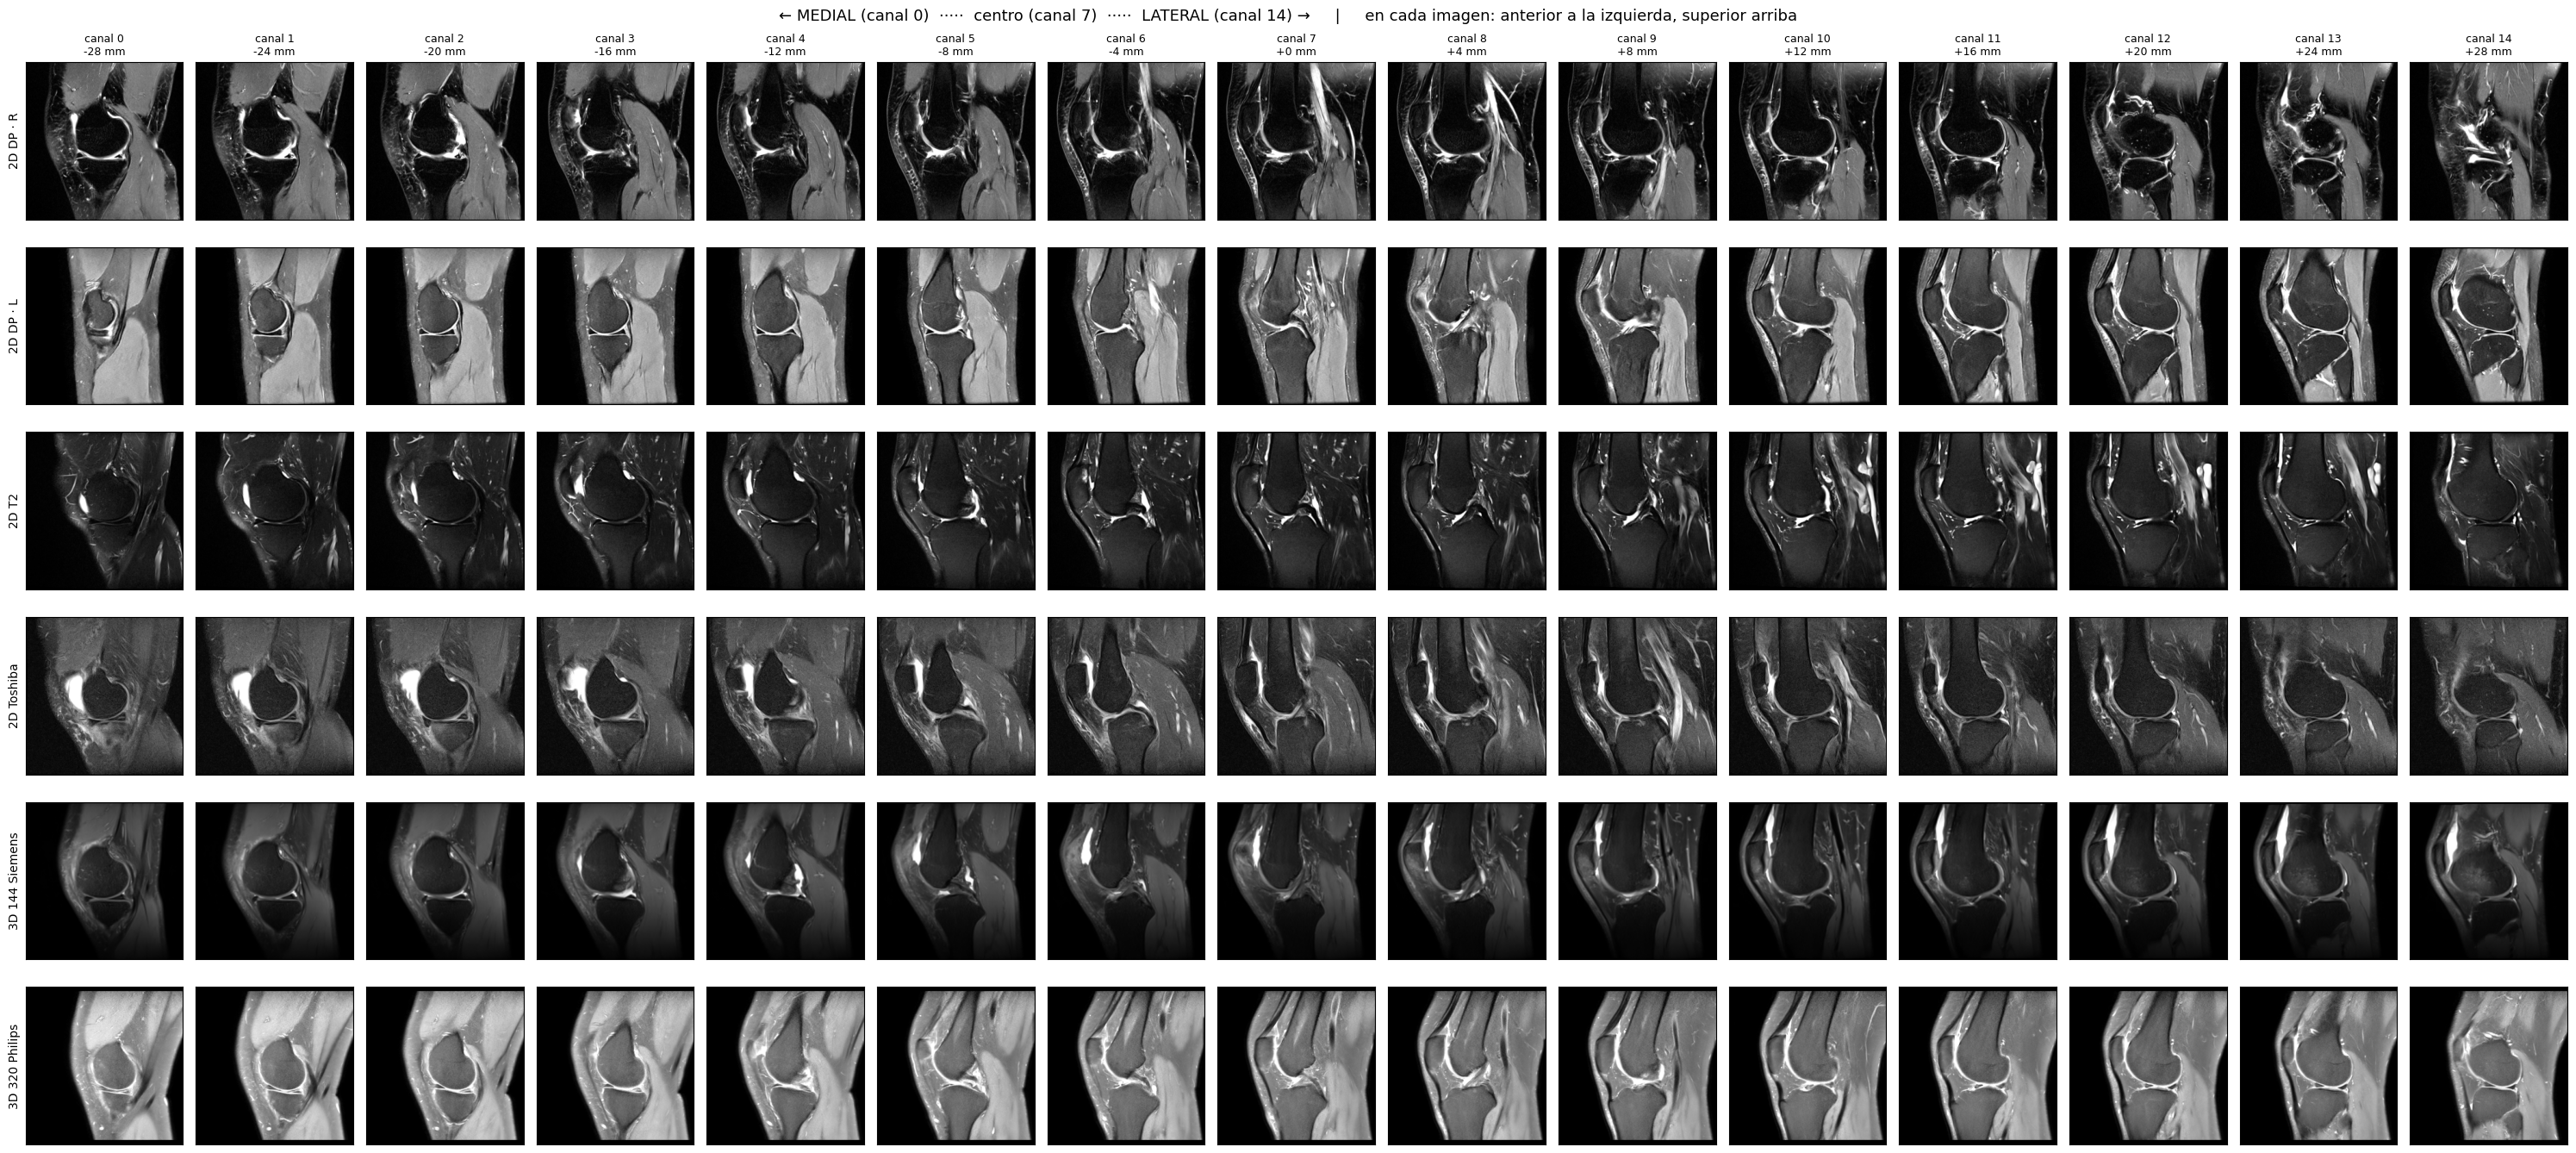

In [6]:
#  preprocesar() en 6 series variadas + revisión visual de los 15 canales
import time

casos = {
    "2D DP · R":      series[(series.n_cortes < 60) & (series.contraste == "DP") & (series.lado_final == "R")].iloc[0],
    "2D DP · L":      series[(series.n_cortes < 60) & (series.contraste == "DP") & (series.lado_final == "L")].iloc[0],
    "2D T2":          series[series.contraste == "T2"].iloc[0],
    "2D Toshiba":     series[series.fabricante == "TOSHIBA"].iloc[0],
    "3D 144 Siemens": series[series.n_cortes == 144].iloc[0],
    "3D 320 Philips": series[series.n_cortes == 320].iloc[0],
}

resultados = {}
for nombre, f in casos.items():
    t0 = time.time()
    x, info = preprocesar(f)
    resultados[nombre] = x
    print(f"{nombre:15s} | {f.fabricante:9s} | lado {f.lado_final} | {f.n_cortes:3d} cortes | "
          f"{f.Filas}×{f.Cols} | {info} | {time.time() - t0:.1f} s")

fig, ax = plt.subplots(len(casos), 15, figsize=(30, 2.3 * len(casos)))
for r, (nombre, x) in enumerate(resultados.items()):
    for c in range(15):
        ax[r, c].imshow(x[c].astype(np.float32), cmap="gray", vmin=0, vmax=1)
        ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
        if r == 0: ax[r, c].set_title(f"canal {c}\n{OFFSETS[c]:+d} mm", fontsize=9)
    ax[r, 0].set_ylabel(nombre, fontsize=10)
fig.suptitle("← MEDIAL (canal 0)  ·····  centro (canal 7)  ·····  LATERAL (canal 14) →     "
             "|     en cada imagen: anterior a la izquierda, superior arriba", fontsize=13)
plt.tight_layout(); plt.show()


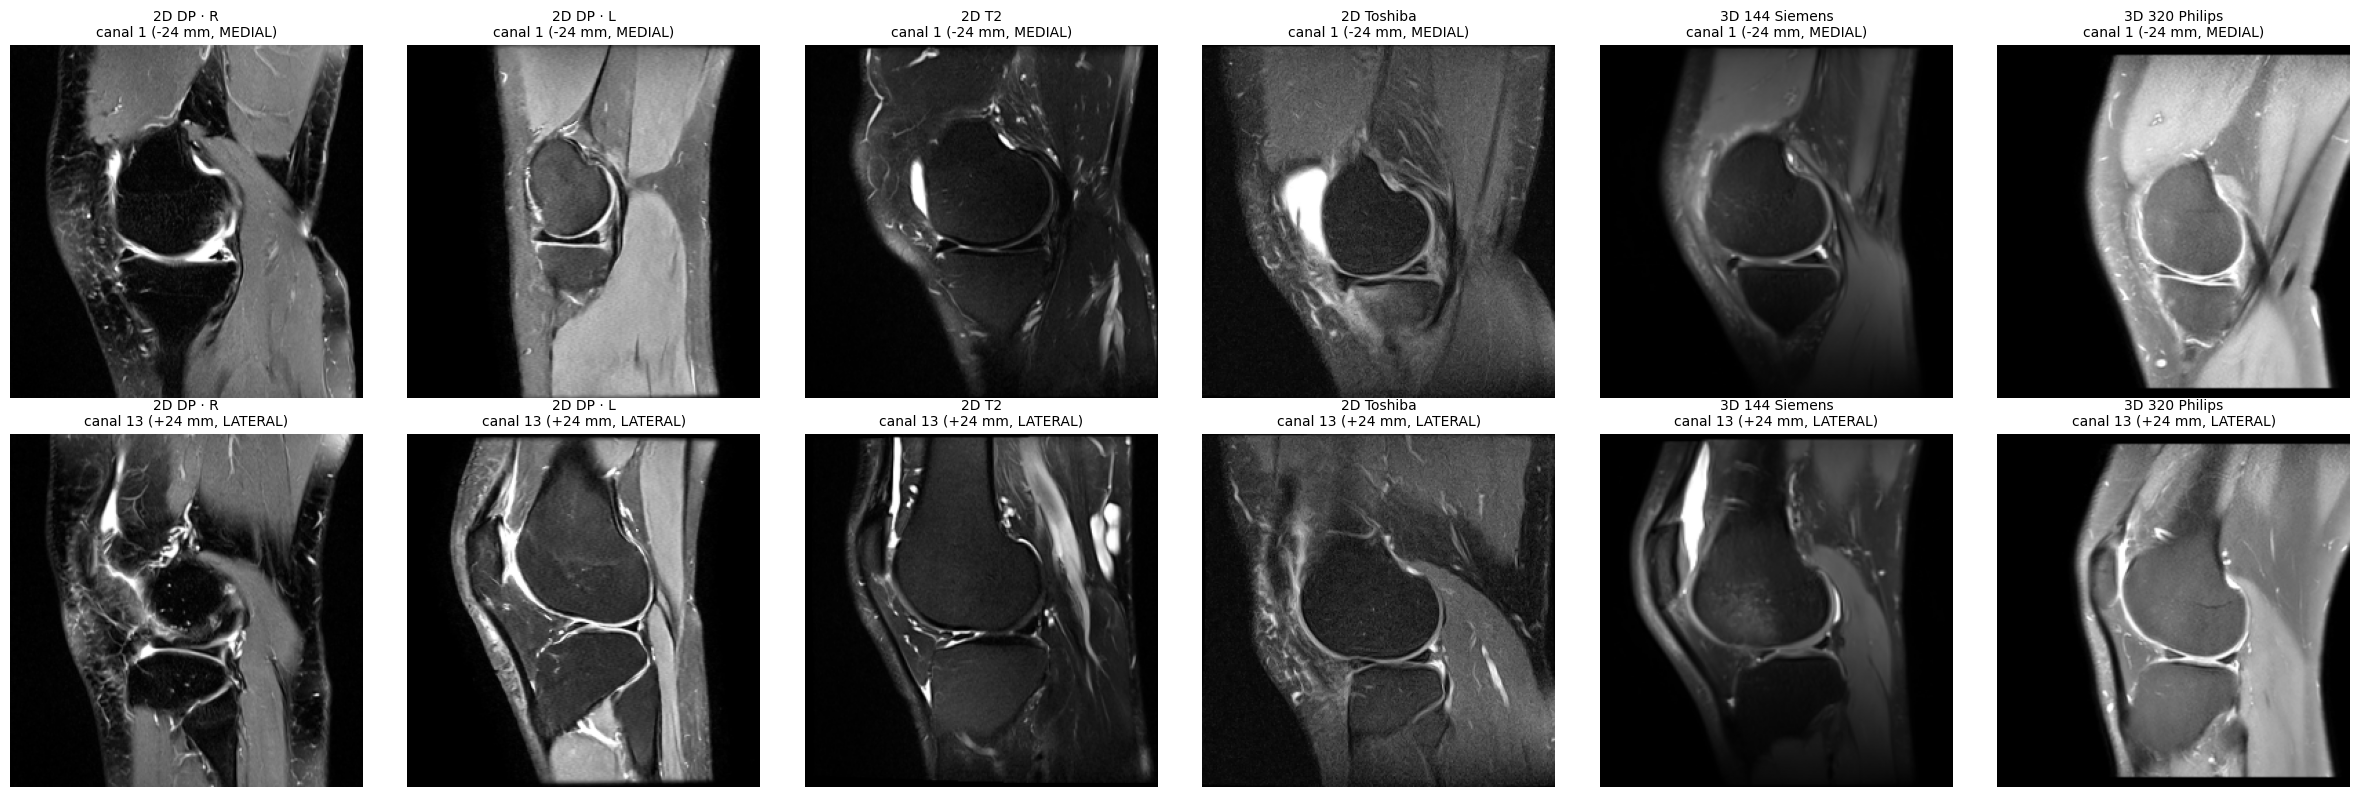

In [7]:
#  (verificación) — Canal 1 (−24 mm, medial) vs canal 13 (+24 mm, lateral), ampliados
fig, ax = plt.subplots(2, len(resultados), figsize=(4 * len(resultados), 8))
for c, (nombre, x) in enumerate(resultados.items()):
    for r, canal in enumerate([1, 13]):
        ax[r, c].imshow(x[canal].astype(np.float32), cmap="gray", vmin=0, vmax=1); ax[r, c].axis("off")
        ax[r, c].set_title(f"{nombre}\ncanal {canal} ({OFFSETS[canal]:+d} mm, {'MEDIAL' if canal == 1 else 'LATERAL'})",
                           fontsize=10)
plt.tight_layout(); plt.show()

### Interpretación — Prueba en 6 series variadas
| Caso | Fabricante | Lado | Cortes | Matriz | Paso | dist_max | Tiempo |
|---|---|---|---|---|---|---|---|
| 2D DP | Siemens | R | 29 | 640² | 3.56 mm | 1.74 mm | 0.4 s |
| 2D DP | GE | L | 41 | 512² | 2.11 mm | 0.98 mm | 1.0 s |
| 2D T2 | Siemens | R | 35 | 320² | 3.22 mm | 1.57 mm | 0.3 s |
| 2D DP | Toshiba | L | 24 | 640² | 3.80 mm | 1.90 mm | 1.1 s |
| 3D DP | Siemens | R | 144 | 192² | 0.89 mm | 0.44 mm | 1.1 s |
| 3D DP | Philips | L | 320 | 640² | 0.40 mm | 0.20 mm | 7.2 s |

- **Orientación en el plano correcta en los 6 casos** (anterior a la izquierda, superior arriba), con 4 fabricantes y ambas rodillas.
- **Cobertura completa:** `dist_max` ≤ paso/2 en todas → ninguna serie se queda corta en el rango ±28 mm.
- Las 3D se ven anatómicamente equivalentes a las 2D en cada canal → el muestreo por mm unifica protocolos.
- Persisten **diferencias de contraste entre protocolos** (la 3D Philips más clara, la T2 más oscura): la normalización
  por percentiles iguala la escala, no el aspecto de cada secuencia → es parte del sesgo de centro/protocolo (req. 7).
- Tiempo estimado para las 656 series: ~10 min en secuencia.


2D DP · R       | lado R | fuente x           | t cubre -50 … +50 mm
2D DP · L       | lado L | fuente x           | t cubre -42 … +42 mm
2D T2           | lado R | fuente x           | t cubre -55 … +55 mm
2D Toshiba      | lado L | fuente visual      | t cubre -44 … +44 mm
3D 144 Siemens  | lado R | fuente x           | t cubre -63 … +63 mm
3D 320 Philips  | lado L | fuente x           | t cubre -64 … +64 mm


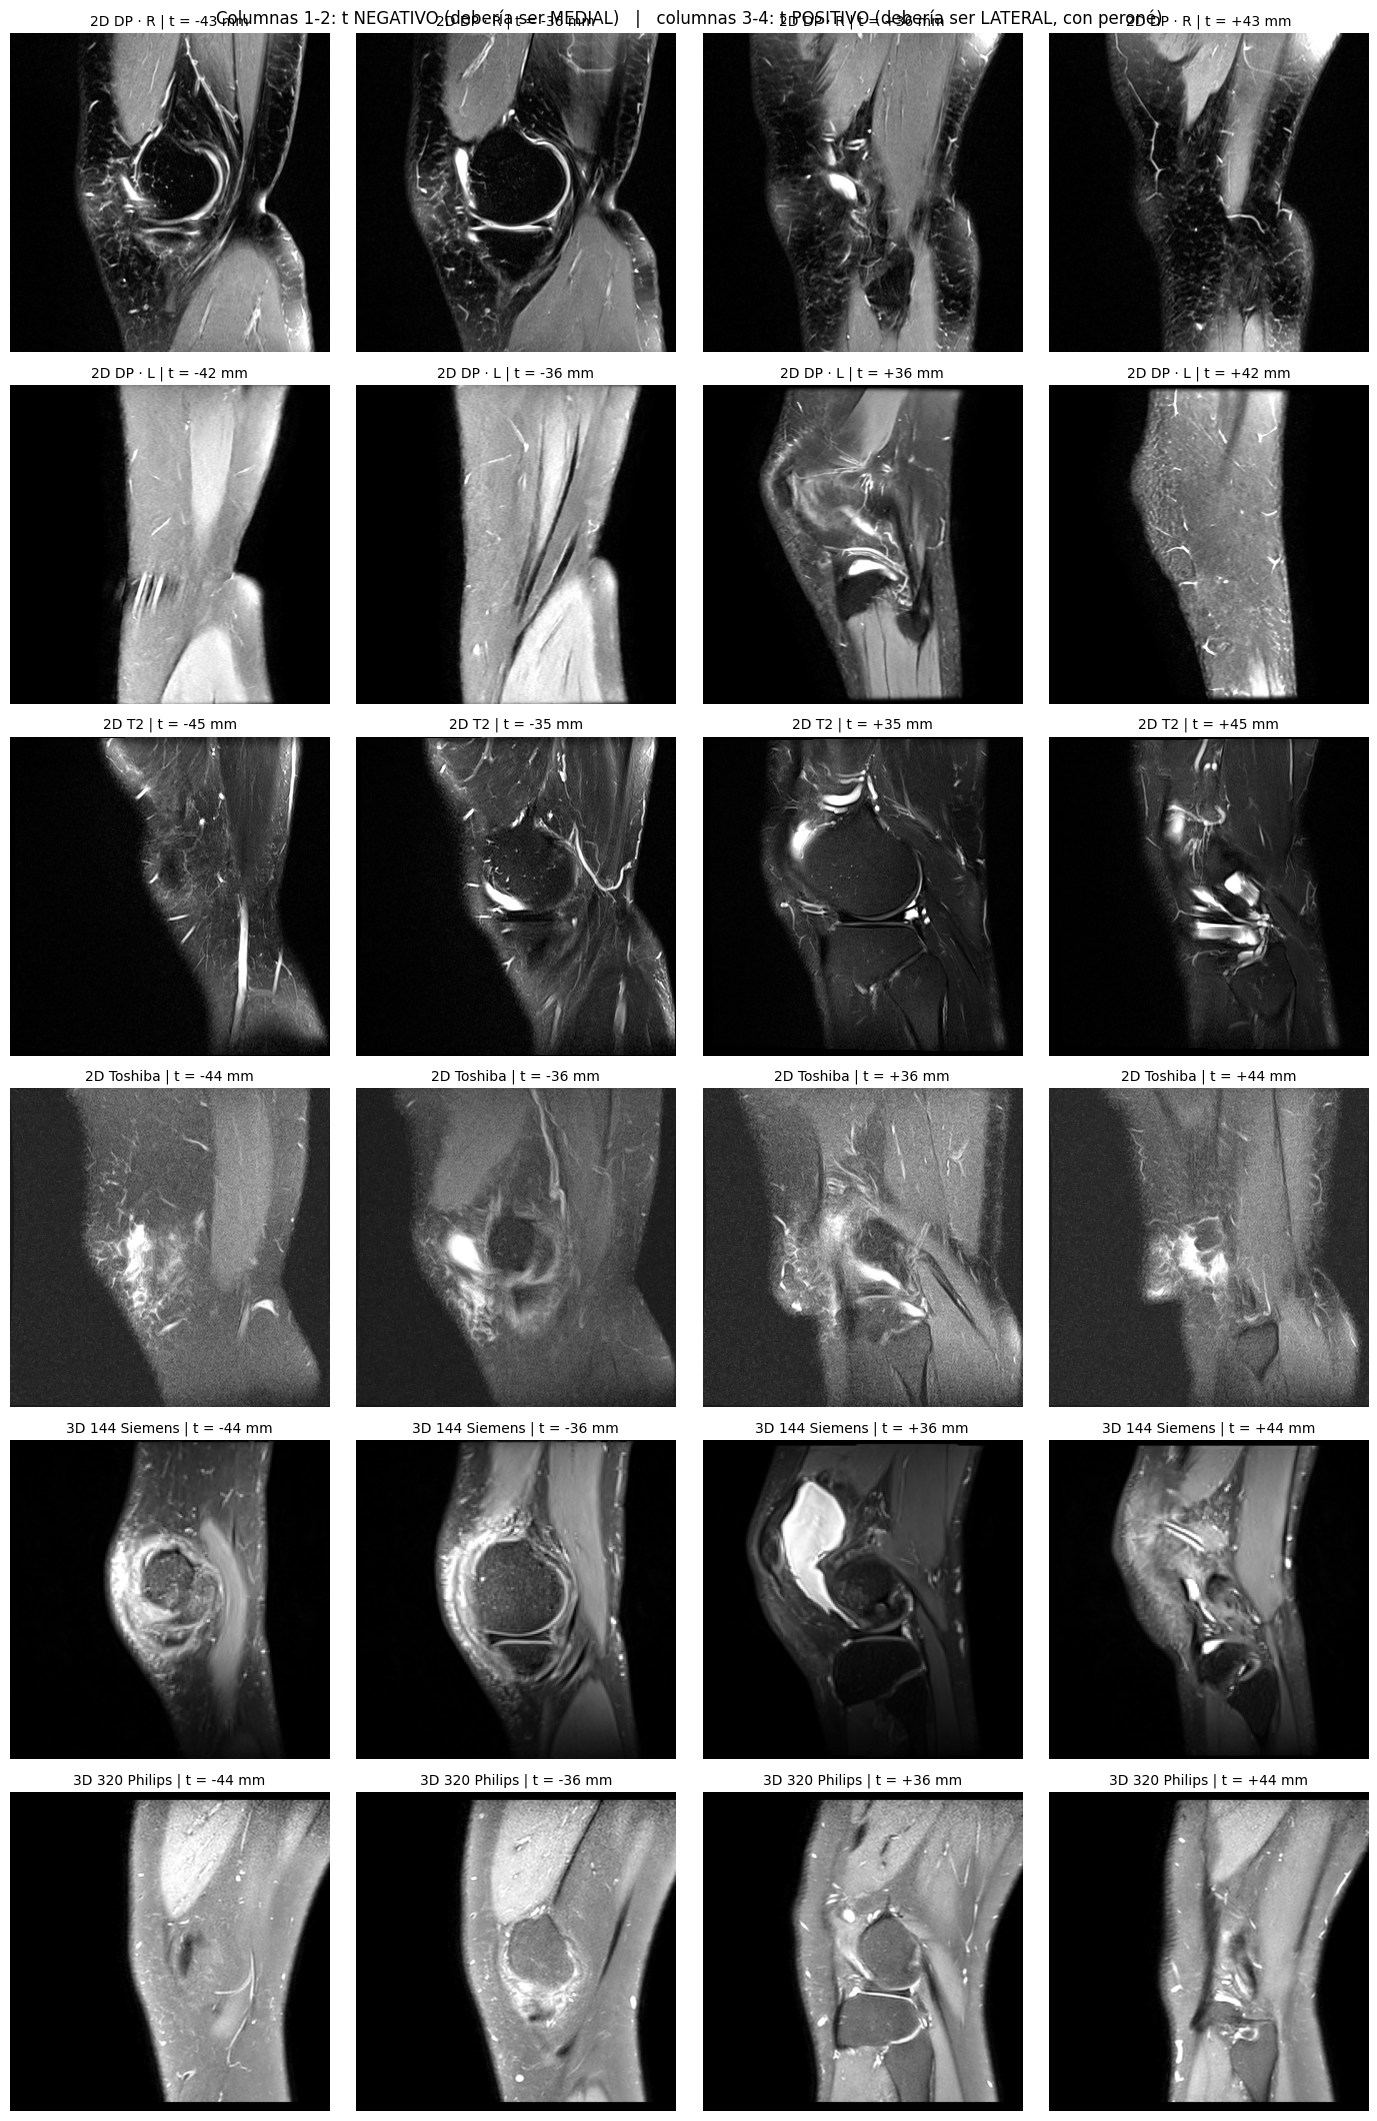

In [8]:
# 10.3d (prueba decisiva) — ¿En qué signo de t aparece el peroné? Debe ser SIEMPRE t > 0 (lateral)
def cortes_en_t(fila, ts=(-44, -36, 36, 44)):
    vol, xs, ori = leer_volumen(fila)
    vol = orientar_plano(vol, ori)
    t = (-1 if fila.lado_final == "R" else 1) * (xs - xs.mean())
    elegidos = [np.argmin(np.abs(t - o)) for o in ts]
    return [(vol[i], t[i]) for i in elegidos], t.min(), t.max()

fig, ax = plt.subplots(len(casos), 4, figsize=(14, 3.6 * len(casos)))
for r, (nombre, f) in enumerate(casos.items()):
    imgs, tmin, tmax = cortes_en_t(f)
    for c, (img, tt) in enumerate(imgs):
        ax[r, c].imshow(img, cmap="gray", vmax=np.percentile(img, 99.5)); ax[r, c].axis("off")
        ax[r, c].set_title(f"{nombre} | t = {tt:+.0f} mm", fontsize=10)
    print(f"{nombre:15s} | lado {f.lado_final} | fuente {f.lado_fuente:11s} | t cubre {tmin:+.0f} … {tmax:+.0f} mm")
fig.suptitle("Columnas 1-2: t NEGATIVO (debería ser MEDIAL)   |   columnas 3-4: t POSITIVO (debería ser LATERAL, con peroné)",
             fontsize=12)
plt.tight_layout(); plt.show()


# PROCESAR LAS 656 SERIES EN PARALELO

In [9]:
# Preprocesar las 656 series en paralelo → /kaggle/working/npy/<StudyInstanceUID>.npy
from concurrent.futures import ThreadPoolExecutor
from tqdm.auto import tqdm

CARPETA = OUT / "npy"
CARPETA.mkdir(exist_ok=True)

def procesar_y_guardar(fila):
    destino = CARPETA / f"{fila.StudyInstanceUID}.npy"
    try:
        x, info = preprocesar(fila)
        np.save(destino, x)
        return {"StudyInstanceUID": fila.StudyInstanceUID, "ok": True, **info, "error": ""}
    except Exception as e:                       # una serie rota no detiene las demás
        return {"StudyInstanceUID": fila.StudyInstanceUID, "ok": False, "error": repr(e)}

t0 = time.time()
with ThreadPoolExecutor(max_workers=8) as pool:
    log = list(tqdm(pool.map(procesar_y_guardar, series.itertuples()), total=len(series), desc="series"))
log = pd.DataFrame(log)
log.to_csv(OUT / "log_npy.csv", index=False)

print(f"Tiempo: {(time.time() - t0) / 60:.1f} min")
print("Correctas:", log["ok"].sum(), "de", len(log))
print(log.loc[~log["ok"], ["StudyInstanceUID", "error"]].to_string(index=False) if (~log["ok"]).any() else "Sin errores")
print("\ndist_max (mm):"); print(log["dist_max"].describe().round(2))
print("\nArchivos .npy:", len(list(CARPETA.glob("*.npy"))),
      "| tamaño total:", round(sum(p.stat().st_size for p in CARPETA.glob("*.npy")) / 1e9, 2), "GB")


series:   0%|          | 0/656 [00:00<?, ?it/s]

Tiempo: 1.8 min
Correctas: 656 de 656
Sin errores

dist_max (mm):
count    656.00
mean       1.66
std        0.49
min        0.02
25%        1.50
50%        1.64
75%        2.00
max        2.72
Name: dist_max, dtype: float64

Archivos .npy: 656 | tamaño total: 1.29 GB


### Interpretación — Preprocesamiento de las 656 series
- **656 de 656 correctas, 0 errores**, en **2.5 min** (8 hilos en paralelo, 1.6 series/s).
- **`dist_max`** (distancia entre la posición pedida y el corte real más cercano): mediana **1.64 mm**, máximo **2.72 mm**.
  - Como cada posición toma el corte más cercano, la distancia máxima esperable es la mitad del paso: con cortes de
    3–5 mm, entre 1.5 y 2.5 mm. El máximo de 2.72 mm corresponde a series de cortes gruesos (~5 mm) → **ninguna serie
    se quedó sin cobertura** en el rango ±28 mm (si no, habría valores de 10 mm o más).
  - Mínimo 0.02 mm: las 3D finas, donde siempre hay un corte casi exacto.
- **656 archivos `.npy`, 1.29 GB** en total (= 656 × 15 × 256 × 256 × 2 bytes, lo esperado).
- `log_npy.csv` guarda, por estudio, el estado, el paso y `dist_max` (trazabilidad para el informe).


Estudios en el índice: 656 | forma correcta: 656 | con NaN: 0 | con canales negros: 0

Media de intensidad por contraste y fabricante:
                       mean  count
contraste fabricante              
DP        CANON_MEC   0.231      6
          FUJIFILM    0.282      5
          GE          0.256    112
          HITACHI     0.209      1
          PHILIPS     0.270    206
          SIEMENS     0.250    203
          TOSHIBA     0.237     38
T2        GE          0.225     36
          GEHC        0.169      6
          SIEMENS     0.181     40
          TOSHIBA     0.222      3


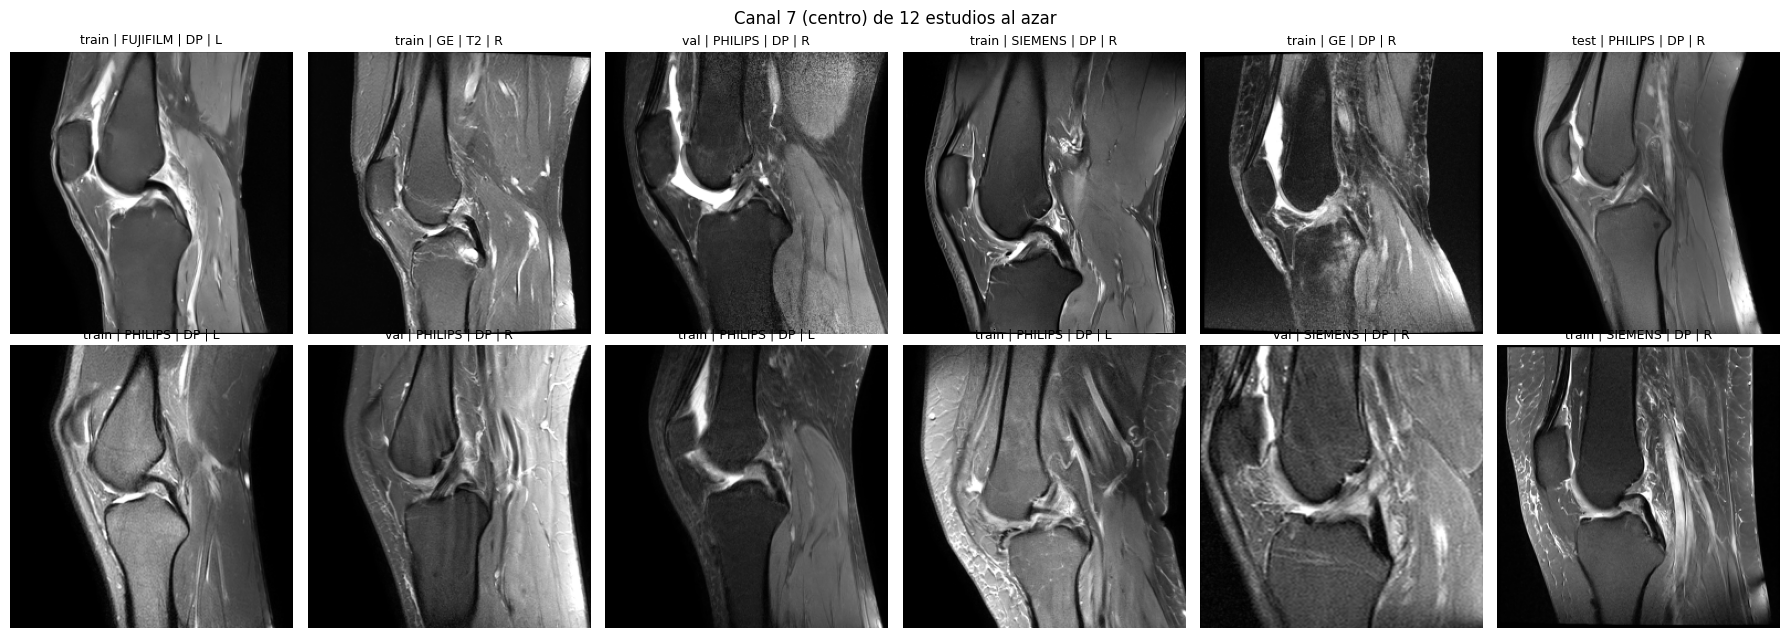

In [10]:
#  — Control de calidad de los 656 .npy + índice para el entrenamiento
LABELS = ["ACL", "MCL", "Medial Meniscus", "Lateral Meniscus", "Medial OA", "Lateral OA",
          "PF OA", "Effusion", "Synovitis", "Baker's", "Contusion", "Fracture"]
etq = pd.read_csv(MIO / "dataset_cnn.csv")

def revisar(uid):
    x = np.load(CARPETA / f"{uid}.npy").astype(np.float32)
    return {"forma_ok": x.shape == (15, 256, 256),
            "hay_nan":  bool(np.isnan(x).any()),
            "media":    round(float(x.mean()), 3),
            "canales_negros": int((x.reshape(15, -1).max(axis=1) < 0.05).sum())}

indice = (series[["StudyInstanceUID", "split", "contraste", "fabricante", "lado_final", "lado_fuente", "n_cortes"]]
          .merge(log[["StudyInstanceUID", "ok", "dist_max"]], on="StudyInstanceUID")
          .merge(etq[["StudyInstanceUID", "idioma", "fuente_etiquetas"] + LABELS], on="StudyInstanceUID"))
indice["archivo"] = "npy/" + indice["StudyInstanceUID"] + ".npy"
indice = pd.concat([indice, pd.DataFrame([revisar(u) for u in indice["StudyInstanceUID"]])], axis=1)

print("Estudios en el índice:", len(indice), "| forma correcta:", indice["forma_ok"].sum(),
      "| con NaN:", indice["hay_nan"].sum(), "| con canales negros:", (indice["canales_negros"] > 0).sum())
print("\nMedia de intensidad por contraste y fabricante:")
print(indice.groupby(["contraste", "fabricante"])["media"].agg(["mean", "count"]).round(3))
indice.to_csv(OUT / "indice_npy.csv", index=False)

# Mosaico: canal central (7) de 12 estudios al azar
muestra = indice.sample(12, random_state=0)
fig, ax = plt.subplots(2, 6, figsize=(18, 6.5))
for a, (_, f) in zip(ax.ravel(), muestra.iterrows()):
    a.imshow(np.load(OUT / f.archivo)[7].astype(np.float32), cmap="gray", vmin=0, vmax=1); a.axis("off")
    a.set_title(f"{f.split} | {f.fabricante} | {f.contraste} | {f.lado_final}", fontsize=9)
plt.suptitle("Canal 7 (centro) de 12 estudios al azar"); plt.tight_layout(); plt.show()


### Interpretación  — Control de calidad y índice
- **656 estudios en el índice**: forma correcta (15, 256, 256) en los 656, **0 con NaN**, **0 con canales negros**
  → todos los archivos son válidos y todos los canales contienen rodilla.
- **Brillo medio tras normalizar** (escala 0–1):
  - DP: 0.21 – 0.28 según el fabricante.
  - T2: 0.17 – 0.23 → algo **más oscura**, como se espera: en T2 FS solo brilla el líquido y el resto del tejido queda
    oscuro. La más baja es GEHC (0.17), la imagen "agua" de una técnica Dixon (`SMART FAT`).
  - La normalización deja las escalas en un **rango parecido**, pero no iguala el aspecto de cada protocolo → sesgo de
    fabricante/protocolo a mencionar en la discusión (req. 7); posible mitigación: aumento de brillo/contraste.
- **Mosaico (canal 7, 12 estudios al azar, 4 fabricantes, DP/T2, R/L, train/val/test):** en todos se ve el **corte
  central** (escotadura con los cruzados, rótula y tendón rotuliano) con la **misma orientación**: anterior a la
  izquierda, fémur arriba.

## RESUMEN
| | |
|---|---|
| Entrada | 656 series Sagital FS (una por estudio) |
| Salida | `npy/<StudyInstanceUID>.npy` → **[15, 256, 256] float16**, canal 0 = medial, 7 = centro, 14 = lateral |
| Índice | `indice_npy.csv`: split, contraste, fabricante, lado, idioma, fuente de etiquetas, 12 etiquetas, ruta, QC |
| Calidad | 656/656 sin errores · cobertura completa (dist_max ≤ 2.72 mm) · 0 NaN · 0 canales vacíos |
| Validación anatómica | orientación en el plano en 6 casos variados + prueba del peroné (lateral siempre en t > 0) |
